# willmarley: choosing a motor, propeller, and battery

Tracks [issue #85](https://github.com/MarMar888/hav/issues/85).

We have three things to buy. Each gets its own section — the raw equations, the inputs
it brings, and a low/high range for every input (nothing is picked). The loop is closed:
the battery's weight counts against the boat, the water's push-back is in the solve, and
the speed that comes out is a power-balanced speed, not a gear-ratio fantasy.

The chain, in words:

> **battery** gives volts and amps (and adds its own weight) → **motor** turns them into
> torque and rpm → **propeller** turns shaft power into pull through the water → the
> **water pushes back** in proportion to all-up weight → speed is where pull and
> push-back balance.

Section 5 draws this as a map. Every number below is computed from the ranges — edit any
bound and re-run.

## 1. The motor

A DC motor is two numbers deep down — `Kv` and `R` — plus two guardrails (`I0`, `I_max`).

```text
Kt  = 60 / (2π · Kv)        torque constant: N·m you get per amp
Q   = Kt · (I − I0)         torque out, for current in (I0 is lost to friction)
rpm = Kv · (V − I · R)      spin rate, for volts in (I·R is lost to the winding)
I  ≤ I_max                  the current guardrail — more amps than this melts it
```

`Kv` is the trade: a high-Kv motor spins faster per volt but makes less torque per
amp. You can't have both — `Kt · Kv` is a constant of nature (60/2π).

input      low     high  unit
Kv         300     1200  rpm/V
R        0.005     0.05  ohm
I0           1        6  A
I_max       50      320  A


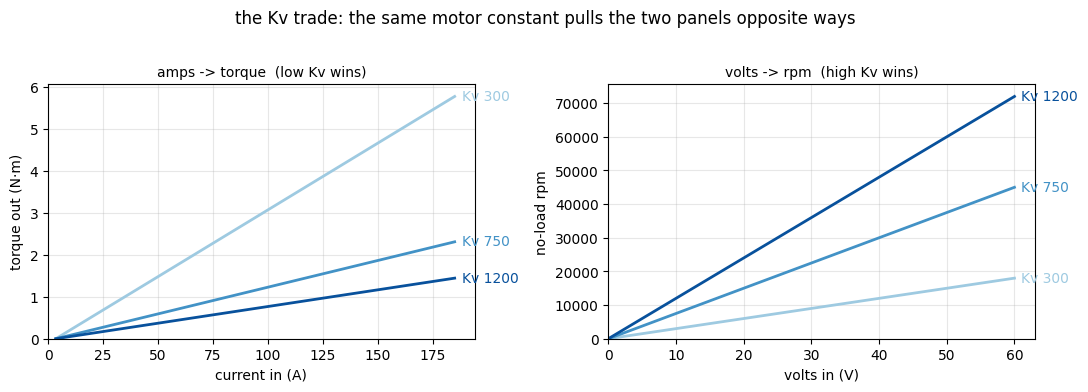

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

RHO = 999.0  # water density, kg/m^3
SEQ = ["#9ecae1", "#4292c6", "#08519c"]  # low / mid / high of one knob, light -> dark

def lo_mid_hi(bounds, key):
    lo, hi = bounds[key]
    return [lo, (lo + hi) / 2, hi]

def show_bounds(bounds, units):
    w = max(len(k) for k in bounds)
    print(f"{'input':<{w}}  {'low':>7}  {'high':>7}  unit")
    for k, (lo, hi) in bounds.items():
        print(f"{k:<{w}}  {lo:>7g}  {hi:>7g}  {units[k]}")

MOTOR_BOUNDS = {
    "Kv":    (300.0, 1200.0),
    "R":     (0.005, 0.050),
    "I0":    (1.0, 6.0),
    "I_max": (50.0, 320.0),
}
MOTOR_UNITS = {"Kv": "rpm/V", "R": "ohm", "I0": "A", "I_max": "A"}
show_bounds(MOTOR_BOUNDS, MOTOR_UNITS)

I0_mid = sum(MOTOR_BOUNDS["I0"]) / 2
Imax_mid = sum(MOTOR_BOUNDS["I_max"]) / 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for Kv, color in zip(lo_mid_hi(MOTOR_BOUNDS, "Kv"), SEQ):
    Kt = 60 / (2 * math.pi * Kv)
    I = np.linspace(I0_mid, Imax_mid, 50)
    ax1.plot(I, Kt * (I - I0_mid), color=color, lw=2)
    ax1.annotate(f"Kv {Kv:g}", (I[-1], Kt * (I[-1] - I0_mid)),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
    V = np.linspace(0, 60, 2)
    ax2.plot(V, Kv * V, color=color, lw=2)
    ax2.annotate(f"Kv {Kv:g}", (V[-1], Kv * V[-1]),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
ax1.set_xlabel("current in (A)"); ax1.set_ylabel("torque out (N·m)")
ax1.set_title("amps -> torque  (low Kv wins)", fontsize=10)
ax2.set_xlabel("volts in (V)"); ax2.set_ylabel("no-load rpm")
ax2.set_title("volts -> rpm  (high Kv wins)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_xlim(left=0); ax.set_ylim(bottom=0)
    ax.margins(x=0.15)
fig.suptitle("the Kv trade: the same motor constant pulls the two panels opposite ways", y=1.02)
plt.tight_layout(); plt.show()

## 2. The propeller

Three raw equations — the load it puts on the motor, how well it converts power to pull,
and the hard ceiling its geometry puts on speed:

```text
Q        = K_Q · ρ · n² · D⁵          torque the water demands to spin it
                                      (n in rev/s, D in meters, ρ = water density)
P_pull   = η_p · P_shaft              pull-through-the-water power, from shaft power
mph_max  = rpm · pitch / 1056         the zero-slip ceiling: a prop can never advance
                                      faster than its own thread (1056: in/min -> mph)
```

What each knob really is:

- **D (diameter)** — the load knob. It enters to the **5th power**, so small diameter
  changes swing the torque demand hugely.
- **K_Q** — one constant per prop. It comes from the propeller's measured curve (model-basin
  series data), and on a real prop it rises with pitch — held independent here, for now.
- **η_p (prop efficiency)** — what fraction of shaft power becomes pull. This also comes
  from the prop's curve; good props on plane run roughly in the 0.5–0.7 band.
- **pitch** — the thread of the screw. It no longer buys speed by itself; it only sets the
  ceiling. Slip is **no longer an input** — section 6 solves it.

input      low     high  unit
K_Q       0.02     0.05  -
D_in         2        5  in
pitch        6       14  in/rev
eta_p      0.5      0.7  -


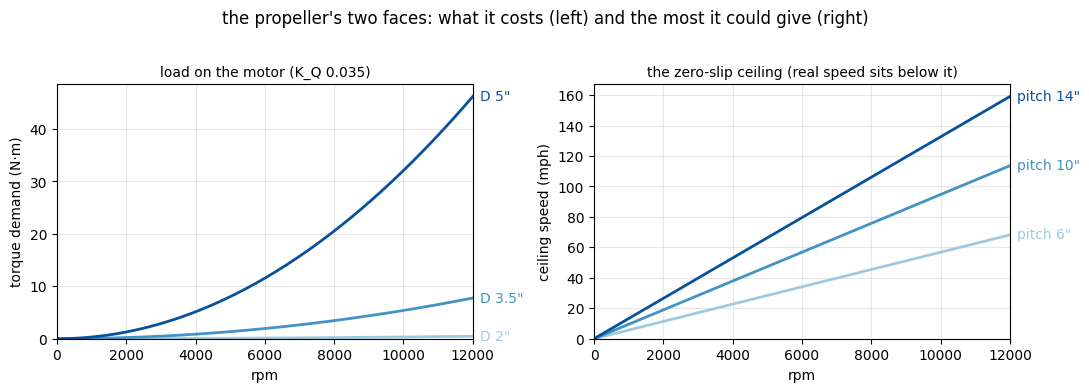

In [2]:
PROP_BOUNDS = {
    "K_Q":   (0.02, 0.05),
    "D_in":  (2.0, 5.0),
    "pitch": (6.0, 14.0),
    "eta_p": (0.5, 0.7),
}
PROP_UNITS = {"K_Q": "-", "D_in": "in", "pitch": "in/rev", "eta_p": "-"}
show_bounds(PROP_BOUNDS, PROP_UNITS)

KQ_mid = sum(PROP_BOUNDS["K_Q"]) / 2
rpm = np.linspace(0, 12000, 200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for D_in, color in zip(lo_mid_hi(PROP_BOUNDS, "D_in"), SEQ):
    Q = KQ_mid * RHO * (rpm / 60) ** 2 * (D_in * 0.0254) ** 5
    ax1.plot(rpm, Q, color=color, lw=2)
    ax1.annotate(f'D {D_in:g}"', (rpm[-1], Q[-1]),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
for pitch, color in zip(lo_mid_hi(PROP_BOUNDS, "pitch"), SEQ):
    mph_max = rpm * pitch / 1056
    ax2.plot(rpm, mph_max, color=color, lw=2)
    ax2.annotate(f'pitch {pitch:g}"', (rpm[-1], mph_max[-1]),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
ax1.set_xlabel("rpm"); ax1.set_ylabel("torque demand (N·m)")
ax1.set_title(f"load on the motor (K_Q {KQ_mid:g})", fontsize=10)
ax2.set_xlabel("rpm"); ax2.set_ylabel("ceiling speed (mph)")
ax2.set_title("the zero-slip ceiling (real speed sits below it)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_xlim(0, rpm[-1]); ax.set_ylim(bottom=0)
    ax.margins(x=0.15)
fig.suptitle("the propeller's two faces: what it costs (left) and the most it could give (right)", y=1.02)
plt.tight_layout(); plt.show()

## 3. The battery

The battery brings volts, amp-hours, and — now that the loop is closed — **its own weight**,
which the boat must carry and the water will charge for.

```text
P_elec  = V · I                  watts drawn from the pack
minutes = 60 · usable · C / I    runtime at a steady current draw
W_batt  = C · V / e_batt         the pack's weight: energy stored ÷ specific energy
                                 (e_batt in Wh per lb of pack)
```

Volts set the motor's rpm headroom. Amp-hours set the minutes — and, with volts, the
weight. There is no free capacity: every amp-hour is carried through the water.

input       low     high  unit
V            20       50  V
C            40      200  Ah
usable      0.7      0.9  -
e_batt       50      100  Wh/lb


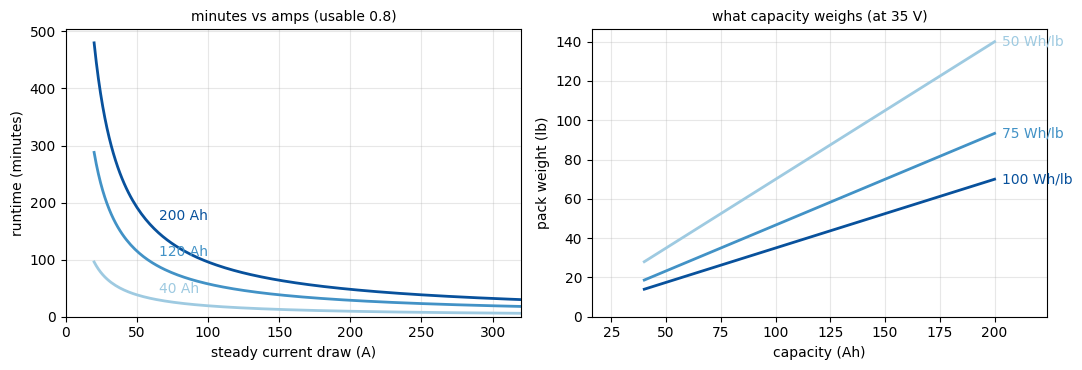

In [3]:
BATT_BOUNDS = {
    "V":      (20.0, 50.0),
    "C":      (40.0, 200.0),
    "usable": (0.7, 0.9),
    "e_batt": (50.0, 100.0),
}
BATT_UNITS = {"V": "V", "C": "Ah", "usable": "-", "e_batt": "Wh/lb"}
show_bounds(BATT_BOUNDS, BATT_UNITS)

usable_mid = sum(BATT_BOUNDS["usable"]) / 2
V_mid = sum(BATT_BOUNDS["V"]) / 2
I = np.linspace(20, 320, 200)
C_axis = np.linspace(*BATT_BOUNDS["C"], 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for C, color in zip(lo_mid_hi(BATT_BOUNDS, "C"), SEQ):
    minutes = 60 * usable_mid * C / I
    ax1.plot(I, minutes, color=color, lw=2)
    x_lab = 60.0
    ax1.annotate(f"{C:g} Ah", (x_lab, 60 * usable_mid * C / x_lab),
                 xytext=(6, 4), textcoords="offset points", color=color)
for e, color in zip(lo_mid_hi(BATT_BOUNDS, "e_batt"), SEQ):
    ax2.plot(C_axis, C_axis * V_mid / e, color=color, lw=2)
    ax2.annotate(f"{e:g} Wh/lb", (C_axis[-1], C_axis[-1] * V_mid / e),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
ax1.set_xlabel("steady current draw (A)"); ax1.set_ylabel("runtime (minutes)")
ax1.set_title(f"minutes vs amps (usable {usable_mid:g})", fontsize=10)
ax2.set_xlabel("capacity (Ah)"); ax2.set_ylabel("pack weight (lb)")
ax2.set_title(f"what capacity weighs (at {V_mid:g} V)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_ylim(bottom=0)
ax1.set_xlim(0, I[-1]); ax2.margins(x=0.15)
plt.tight_layout(); plt.show()

## 4. The water and the weight

The water's push-back is no longer undefined — on plane it is just the all-up weight
divided by how efficiently the hull rides (its lift-to-drag ratio):

```text
W       = W_hull + W_batt        all-up weight in the water (hull+motor+prop+people, plus the pack)
R_water = W / (L/D)              resistance on plane, lbf
P_tow   = R_water · speed        the towing bill the motor's shaft power must pay
```

A hull that planes pretty well holds **L/D ≈ 5–6** just after it gets on plane; driven
hard, skin friction (growing with speed²) pulls it toward **~2.5**. That whole span is an
input range below, so the model carries the uncertainty instead of hiding it.

input       low     high  unit
W_hull       40      100  lb
LD          2.5      6.5  -


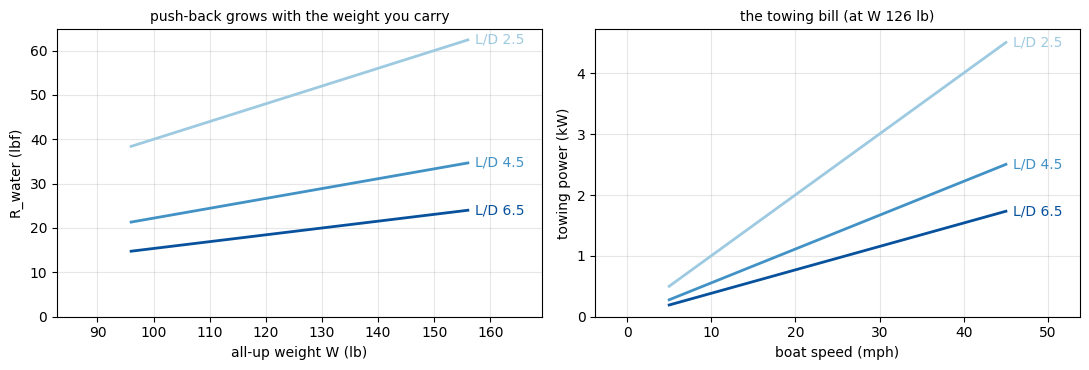

In [4]:
HULL_BOUNDS = {
    "W_hull": (40.0, 100.0),
    "LD":     (2.5, 6.5),
}
HULL_UNITS = {"W_hull": "lb", "LD": "-"}
show_bounds(HULL_BOUNDS, HULL_UNITS)

e_mid = sum(BATT_BOUNDS["e_batt"]) / 2
C_mid = sum(BATT_BOUNDS["C"]) / 2
W_batt_mid = C_mid * V_mid / e_mid
W_span = np.linspace(HULL_BOUNDS["W_hull"][0] + W_batt_mid,
                     HULL_BOUNDS["W_hull"][1] + W_batt_mid, 100)
W_mid = W_span.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for LD, color in zip(lo_mid_hi(HULL_BOUNDS, "LD"), SEQ):
    ax1.plot(W_span, W_span / LD, color=color, lw=2)
    ax1.annotate(f"L/D {LD:g}", (W_span[-1], W_span[-1] / LD),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
v = np.linspace(5, 45, 100)
for LD, color in zip(lo_mid_hi(HULL_BOUNDS, "LD"), SEQ):
    R_N = (W_mid / LD) * 4.4482
    ax2.plot(v, R_N * v * 0.44704 / 1000, color=color, lw=2)
    ax2.annotate(f"L/D {LD:g}", (v[-1], R_N * v[-1] * 0.44704 / 1000),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
ax1.set_xlabel("all-up weight W (lb)"); ax1.set_ylabel("R_water (lbf)")
ax1.set_title("push-back grows with the weight you carry", fontsize=10)
ax2.set_xlabel("boat speed (mph)"); ax2.set_ylabel("towing power (kW)")
ax2.set_title(f"the towing bill (at W {W_mid:.0f} lb)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_ylim(bottom=0)
    ax.margins(x=0.22)
plt.tight_layout(); plt.show()

## 5. The map: how everything connects

One picture of the whole model — the ontology. Left column: every input, colored by which
purchase (or the hull) it belongs to. Middle: the quantities the equations build from them.
Right: what you actually care about. **Every arrow is one of the raw equations above.**

Worth tracing with a finger: `V` and `C` each feed **two** paths — volts buy rpm *and*
weigh the pack down; amp-hours buy minutes *and* weigh the pack down. That double life is
why the battery can't be chosen on runtime alone.

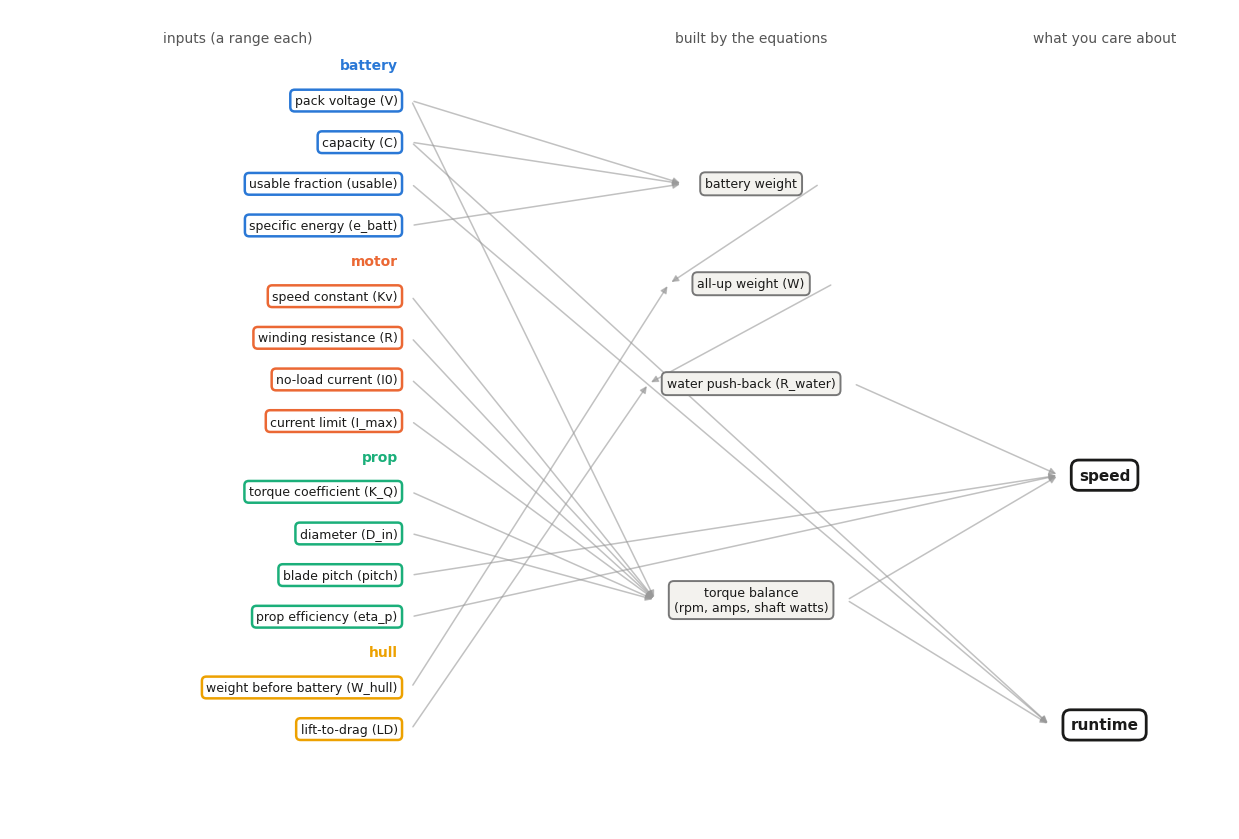

In [5]:
GROUPS = {  # validated categorical palette: identity, fixed order
    "battery": "#2a78d6", "motor": "#eb6834", "prop": "#1baf7a", "hull": "#eda100",
}
LABELS = {  # long name for every short input symbol
    "V": "pack voltage", "C": "capacity", "usable": "usable fraction", "e_batt": "specific energy",
    "Kv": "speed constant", "R": "winding resistance", "I0": "no-load current", "I_max": "current limit",
    "K_Q": "torque coefficient", "D_in": "diameter", "pitch": "blade pitch", "eta_p": "prop efficiency",
    "W_hull": "weight before battery", "LD": "lift-to-drag",
}
INPUT_GROUPS = [
    ("battery", list(BATT_BOUNDS)),
    ("motor",   list(MOTOR_BOUNDS)),
    ("prop",    list(PROP_BOUNDS)),
    ("hull",    list(HULL_BOUNDS)),
]
TB = "torque balance\n(rpm, amps, shaft watts)"
MID_NODES = {  # name: y
    "battery weight": 15.0,
    "all-up weight (W)": 12.6,
    "water push-back (R_water)": 10.2,
    TB: 5.0,
}
OUT_NODES = {"speed": 8.0, "runtime": 2.0}
EDGES = [
    ("C", "battery weight"), ("V", "battery weight"), ("e_batt", "battery weight"),
    ("W_hull", "all-up weight (W)"), ("battery weight", "all-up weight (W)"),
    ("all-up weight (W)", "water push-back (R_water)"), ("LD", "water push-back (R_water)"),
    ("Kv", TB), ("R", TB), ("I0", TB), ("I_max", TB), ("V", TB), ("K_Q", TB), ("D_in", TB),
    (TB, "speed"), ("eta_p", "speed"), ("water push-back (R_water)", "speed"), ("pitch", "speed"),
    (TB, "runtime"), ("C", "runtime"), ("usable", "runtime"),
]
HW = {  # half-widths of middle/output boxes, so arrows stop at the edge
    "battery weight": 0.30, "all-up weight (W)": 0.36, "water push-back (R_water)": 0.45,
    TB: 0.42, "speed": 0.20, "runtime": 0.24,
}

pos = {}
y = 17.0
for gname, keys in INPUT_GROUPS:
    for k in keys:
        pos[k] = (0.0, y); y -= 1.0
    y -= 0.7  # gap between groups
for name, ny in MID_NODES.items():
    pos[name] = (1.55, ny)
for name, ny in OUT_NODES.items():
    pos[name] = (3.1, ny)

fig, ax = plt.subplots(figsize=(12.5, 8.5))
for a, b in EDGES:
    (xa, ya), (xb, yb) = pos[a], pos[b]
    x_start = xa + HW.get(a, 0.06)
    ax.annotate("", xy=(xb - HW[b], yb), xytext=(x_start, ya),
                arrowprops=dict(arrowstyle="-|>", color="#999999", alpha=0.6, lw=1.1))
for gname, keys in INPUT_GROUPS:
    color = GROUPS[gname]
    ys = [pos[k][1] for k in keys]
    ax.text(0.0, max(ys) + 0.75, gname, color=color, fontsize=10, fontweight="bold", ha="right")
    for k in keys:
        ax.text(pos[k][0], pos[k][1], f"{LABELS[k]} ({k})", ha="right", va="center",
                fontsize=9, color="#1a1a19",
                bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=color, lw=1.8))
for name in MID_NODES:
    ax.text(*pos[name], name, ha="center", va="center", fontsize=9, color="#1a1a19",
            bbox=dict(boxstyle="round,pad=0.4", fc="#f3f2ee", ec="#777777", lw=1.4))
for name in OUT_NODES:
    ax.text(*pos[name], name, ha="center", va="center", fontsize=11, color="#1a1a19",
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#1a1a19", lw=2))
ax.text(-0.7, 18.4, "inputs (a range each)", ha="center", fontsize=10, color="#555555")
ax.text(1.55, 18.4, "built by the equations", ha="center", fontsize=10, color="#555555")
ax.text(3.1, 18.4, "what you care about", ha="center", fontsize=10, color="#555555")
ax.set_xlim(-1.7, 3.65); ax.set_ylim(-0.5, 19.2); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Bring it together

Five steps, in the order the physics runs:

```text
1  torque balance   a·rpm² + b·rpm = c  ->  rpm, amps, torque
                    a = K_Q·ρ·D⁵/3600,  b = Kt/(Kv·R),  c = Kt·(V/R − I0)
                    (if amps > I_max: torque pins at Kt·(I_max − I0), rpm from the prop alone)
2  shaft power      P_shaft = torque · 2π · rpm / 60
3  power balance    speed = η_p · P_shaft / R_water      <- the water finally gets a vote
4  ceiling check    speed ≤ rpm · pitch / 1056,  slip = speed / ceiling   (slip is an OUTPUT)
5  runtime          minutes = 60 · usable · C / amps
```

No design point is picked or printed here — the charts below show the whole space.

In [6]:
BOUNDS = {**MOTOR_BOUNDS, **PROP_BOUNDS, **BATT_BOUNDS, **HULL_BOUNDS}
UNITS = {**MOTOR_UNITS, **PROP_UNITS, **BATT_UNITS, **HULL_UNITS}
CENTER = {k: (lo + hi) / 2 for k, (lo, hi) in BOUNDS.items()}  # reference for sweeps only

def steady_state(Kv, R, I0, I_max, V, K_Q, D_in, pitch, eta_p, C, usable, e_batt, W_hull, LD):
    Kt = 60 / (2 * math.pi * Kv)
    a = K_Q * RHO * (D_in * 0.0254) ** 5 / 3600
    b = Kt / (Kv * R)
    c = Kt * (V / R - I0)
    rpm = (-b + math.sqrt(b * b + 4 * a * c)) / (2 * a)
    I = (V - rpm / Kv) / R
    limited = I > I_max
    if limited:
        I = I_max
        torque = Kt * (I_max - I0)
        rpm = 60 * math.sqrt(torque / (K_Q * RHO * (D_in * 0.0254) ** 5))
    else:
        torque = Kt * (I - I0)
    shaft_w = torque * 2 * math.pi * rpm / 60
    W_batt = C * V / e_batt
    W = W_hull + W_batt
    R_water_N = (W / LD) * 4.4482
    v_ms = eta_p * shaft_w / R_water_N
    ceiling_mph = rpm * pitch / 1056
    mph = v_ms / 0.44704
    capped = mph > ceiling_mph
    if capped:
        mph = ceiling_mph
    slip = mph / ceiling_mph
    return dict(rpm=rpm, torque=torque, I=I, limited=limited, shaft_w=shaft_w,
                elec_w=V * I, eff=shaft_w / (V * I), W_batt=W_batt, W=W,
                R_lbf=W / LD, mph=mph, capped=capped, slip=slip,
                minutes=60 * usable * C / I)

def solve(**over):
    return steady_state(**{**CENTER, **over})

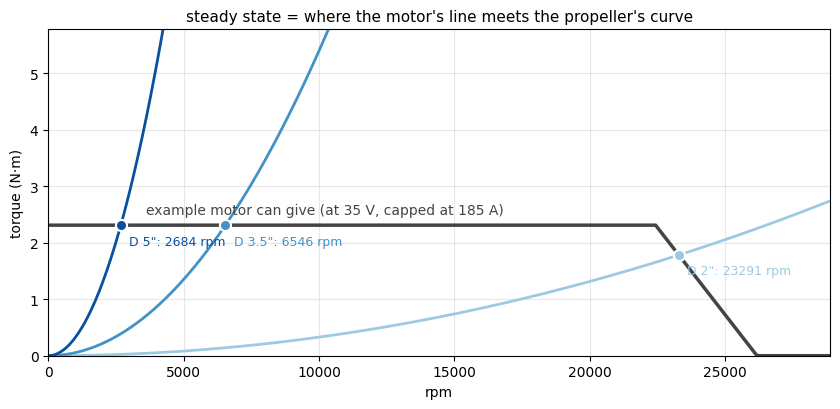

In [7]:
# the mechanism: a mid-range example motor's available torque vs the propeller's demand
Kv, R, I0, I_max, V = (CENTER[k] for k in ("Kv", "R", "I0", "I_max", "V"))
Kt = 60 / (2 * math.pi * Kv)
rpm_free = Kv * V
rpm_axis = np.linspace(1, 1.1 * rpm_free, 400)
I_avail = np.clip((V - rpm_axis / Kv) / R, 0, I_max)
Q_motor = np.maximum(Kt * (I_avail - I0), 0)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(rpm_axis, Q_motor, color="#444444", lw=2.5)
ax.annotate(f"example motor can give (at {V:g} V, capped at {I_max:g} A)",
            (rpm_axis[len(rpm_axis) // 8], Kt * (I_max - I0)),
            xytext=(0, 8), textcoords="offset points", color="#444444")
for D_in, color in zip(lo_mid_hi(PROP_BOUNDS, "D_in"), SEQ):
    Q_prop = CENTER["K_Q"] * RHO * (rpm_axis / 60) ** 2 * (D_in * 0.0254) ** 5
    ax.plot(rpm_axis, Q_prop, color=color, lw=2)
    op = solve(D_in=D_in)
    ax.plot(op["rpm"], op["torque"], "o", color=color, ms=8,
            markeredgecolor="white", markeredgewidth=1.5, zorder=5)
    ax.annotate(f'D {D_in:g}": {op["rpm"]:.0f} rpm', (op["rpm"], op["torque"]),
                xytext=(6, -14), textcoords="offset points", color=color, fontsize=9)
ax.set_xlabel("rpm"); ax.set_ylabel("torque (N·m)")
ax.set_title("steady state = where the motor's line meets the propeller's curve", fontsize=11)
ax.set_xlim(0, rpm_axis[-1]); ax.set_ylim(0, 2.5 * Kt * (I_max - I0))
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

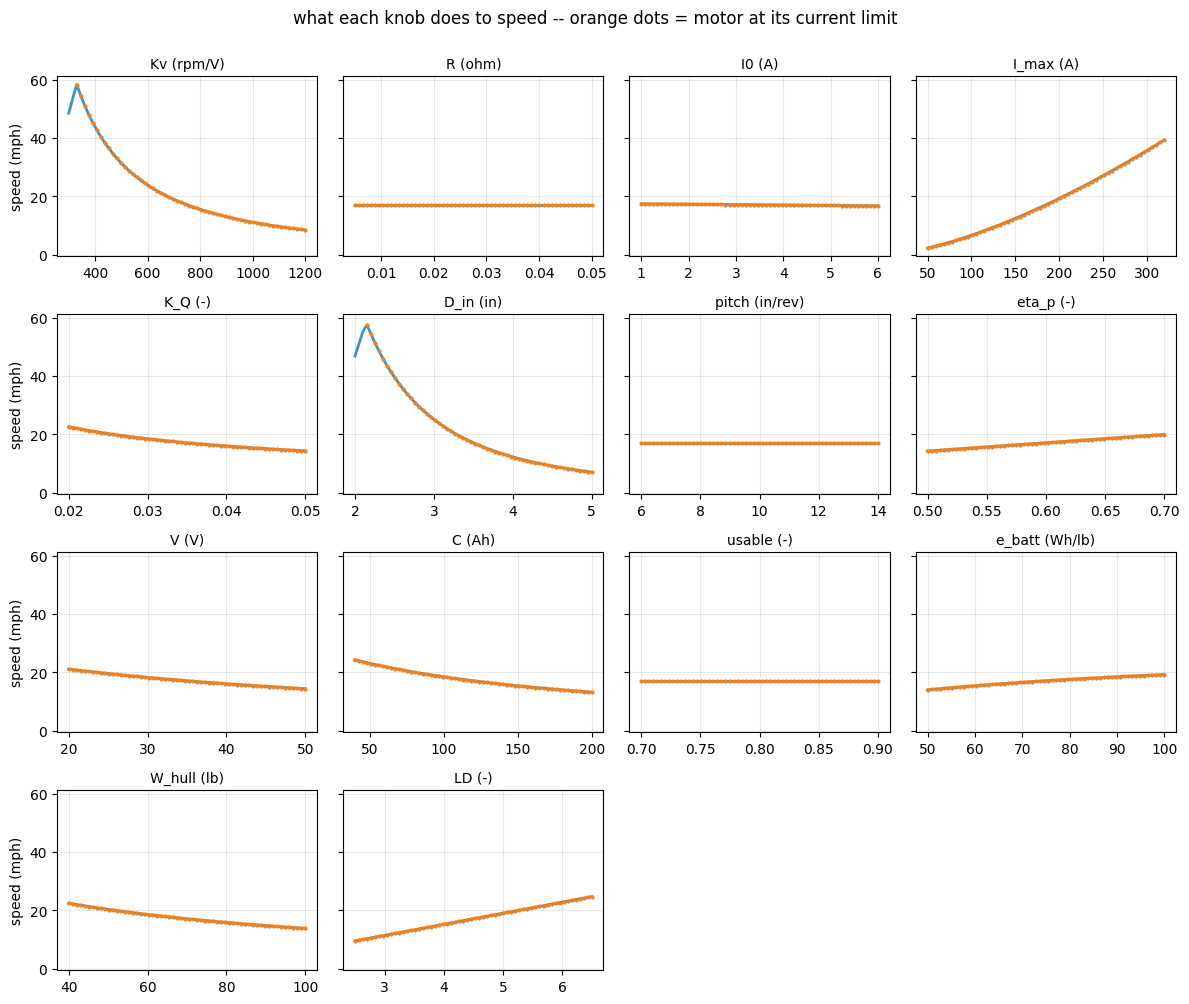

In [8]:
# one panel per input: sweep it across its range, everything else held mid-range
fig, axes = plt.subplots(4, 4, figsize=(12, 10), sharey=True)
for key, ax in zip(BOUNDS, axes.flat):
    lo, hi = BOUNDS[key]
    xs = np.linspace(lo, hi, 60)
    res = [solve(**{key: x}) for x in xs]
    ys = np.array([r["mph"] for r in res])
    lim = np.array([r["limited"] for r in res])
    ax.plot(xs, ys, color="#4292c6", lw=2)
    if lim.any():
        ax.plot(xs[lim], ys[lim], ".", color="tab:orange", ms=4)
    ax.set_title(f"{key} ({UNITS[key]})", fontsize=10)
    ax.grid(alpha=0.3)
for ax in axes.flat[len(BOUNDS):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("speed (mph)")
fig.suptitle("what each knob does to speed -- orange dots = motor at its current limit", y=1.0)
plt.tight_layout(); plt.show()

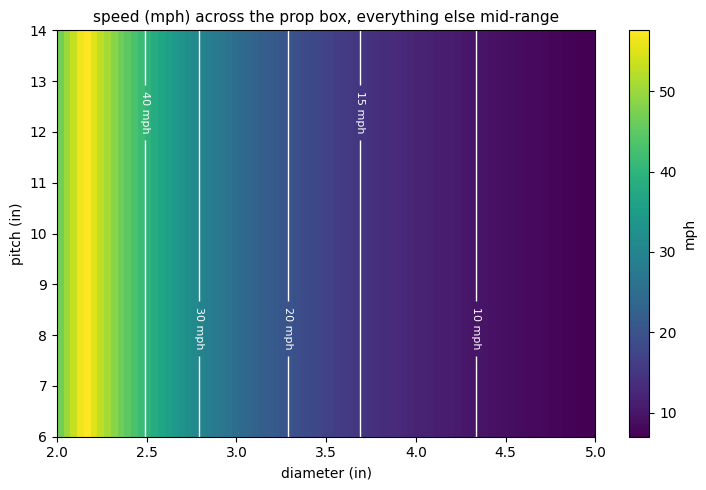

the zero-slip ceiling never binds in this box: pitch only needs to be 'enough'


In [9]:
# the two numbers printed on a propeller, with the water in the loop
D_axis = np.linspace(*PROP_BOUNDS["D_in"], 80)
P_axis = np.linspace(*PROP_BOUNDS["pitch"], 80)
res = [[solve(D_in=D, pitch=p) for D in D_axis] for p in P_axis]
speed = np.array([[r["mph"] for r in row] for row in res])
capped = np.array([[r["capped"] for r in row] for row in res])

fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(speed, origin="lower", aspect="auto", cmap="viridis",
               extent=[D_axis[0], D_axis[-1], P_axis[0], P_axis[-1]])
levels = [lv for lv in (5, 10, 15, 20, 30, 40) if speed.min() < lv < speed.max()]
if levels:
    cs = ax.contour(D_axis, P_axis, speed, levels=levels, colors="white", linewidths=1)
    ax.clabel(cs, fmt="%g mph", fontsize=8)
if capped.any() and not capped.all():
    ax.contour(D_axis, P_axis, capped.astype(float), levels=[0.5],
               colors="white", linewidths=1.5, linestyles="dashed")
ax.set_xlabel("diameter (in)"); ax.set_ylabel("pitch (in)")
ax.set_title("speed (mph) across the prop box, everything else mid-range", fontsize=11)
fig.colorbar(im, ax=ax, label="mph")
plt.tight_layout(); plt.show()

if capped.any():
    frac = capped.mean()
    print(f"dashed line: below it the zero-slip ceiling binds -- not enough pitch to use the "
          f"power ({frac:.0%} of this box)")
else:
    print("the zero-slip ceiling never binds in this box: pitch only needs to be 'enough'")

## 7. How the variables move together

The map (section 5) shows *structure*; this shows *strength*. Sample every input uniformly
across its range — thousands of whole-model solves scattered through the input space — and
correlate each input with each output. Deep red: raising the input raises the output.
Deep blue: raising it lowers the output. Near white: it barely matters there.

This is the shopping cheat-sheet: a column tells you which knobs actually move that
outcome, and the `V` and `C` rows show their double lives from the map playing out.

speed (mph)    across the whole space:  p10    3.4   median   15.4   p90   51.3
runtime (min)  across the whole space:  p10   14.2   median   34.4   p90   92.3
amps (A)       across the whole space:  p10   66.8   median  164.0   p90  283.3
weight (lb)    across the whole space:  p10   85.7   median  124.3   p90  174.9


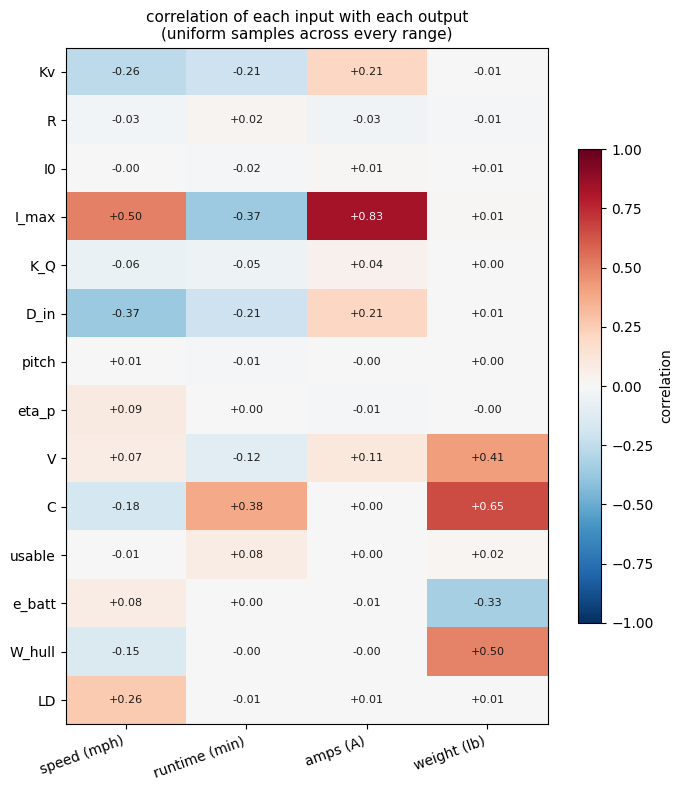

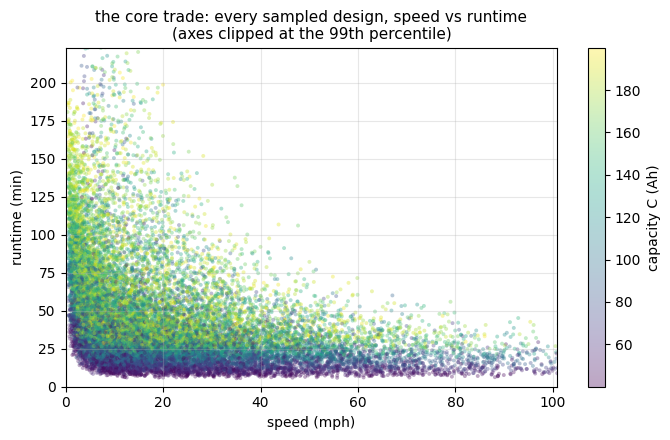

In [10]:
rng = np.random.default_rng(0)
N = 20000
samples = {k: rng.uniform(lo, hi, N) for k, (lo, hi) in BOUNDS.items()}
runs = [steady_state(**{k: samples[k][i] for k in BOUNDS}) for i in range(N)]
OUT = {"speed (mph)": "mph", "runtime (min)": "minutes", "amps (A)": "I", "weight (lb)": "W"}
outs = {label: np.array([r[key] for r in runs]) for label, key in OUT.items()}

for label, arr in outs.items():
    p10, p50, p90 = np.percentile(arr, [10, 50, 90])
    print(f"{label:<14} across the whole space:  p10 {p10:6.1f}   median {p50:6.1f}   p90 {p90:6.1f}")

corr = np.array([[np.corrcoef(samples[k], arr)[0, 1] for arr in outs.values()]
                 for k in BOUNDS])
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(outs))); ax.set_xticklabels(outs.keys(), rotation=20, ha="right")
ax.set_yticks(range(len(BOUNDS))); ax.set_yticklabels(BOUNDS.keys())
for i in range(len(BOUNDS)):
    for j in range(len(outs)):
        ax.text(j, i, f"{corr[i, j]:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr[i, j]) > 0.55 else "#1a1a19")
ax.set_title("correlation of each input with each output\n(uniform samples across every range)",
             fontsize=11)
fig.colorbar(im, ax=ax, label="correlation", shrink=0.7)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(outs["speed (mph)"], outs["runtime (min)"], c=samples["C"],
                cmap="viridis", s=8, alpha=0.35, edgecolors="none")
ax.set_xlim(0, np.percentile(outs["speed (mph)"], 99))
ax.set_ylim(0, np.percentile(outs["runtime (min)"], 99))
ax.set_xlabel("speed (mph)"); ax.set_ylabel("runtime (min)")
ax.set_title("the core trade: every sampled design, speed vs runtime\n(axes clipped at the 99th percentile)", fontsize=11)
ax.grid(alpha=0.3)
fig.colorbar(sc, ax=ax, label="capacity C (Ah)")
plt.tight_layout(); plt.show()

## 8. Conclusions: the valid space and the ideal space

Two different "good"s, kept apart on purpose:

- **Valid** = meets the requirements we set for the boat (edit them below) *and* stays
  where the model's own assumptions hold — the sanity bounds: a motor that isn't mostly
  a heater, a prop that isn't absurdly over-pitched.
- **Ideal** = among the valid designs, the ones nothing beats on both speed *and* runtime
  at once — the Pareto front of the core trade.

Everything here is recomputed from the samples: change a requirement, a sanity bound, or
any input range above, re-run, and the conclusions reshape themselves.

In [11]:
# what we demand of the boat (edit freely), and where the model can be trusted
REQS = {"min_speed_mph": 15.0, "min_runtime_min": 20.0, "max_weight_lb": 160.0}
SANITY = {"min_motor_eff": 0.5, "min_slip": 0.5, "max_speed_mph": 45.0}

eff_s = np.array([r["eff"] for r in runs])
slip_s = np.array([r["slip"] for r in runs])
spd = outs["speed (mph)"]; rt = outs["runtime (min)"]
wt = outs["weight (lb)"]; amps = outs["amps (A)"]

checks = {
    f"speed >= {REQS['min_speed_mph']:g} mph  (fast enough to bother)": spd >= REQS["min_speed_mph"],
    f"runtime >= {REQS['min_runtime_min']:g} min  (long enough to matter)": rt >= REQS["min_runtime_min"],
    f"weight <= {REQS['max_weight_lb']:g} lb  (still a small boat)": wt <= REQS["max_weight_lb"],
    f"motor eff >= {SANITY['min_motor_eff']:g}  (less heat than shaft power)": eff_s >= SANITY["min_motor_eff"],
    f"slip >= {SANITY['min_slip']:g}  (prop not absurdly over-pitched)": slip_s >= SANITY["min_slip"],
    f"speed <= {SANITY['max_speed_mph']:g} mph  (past this, constant L/D is fiction)": spd <= SANITY["max_speed_mph"],
}
valid = np.ones(N, dtype=bool)
w = max(len(k) for k in checks)
for name, m in checks.items():
    print(f"{name:<{w}}   passes {m.mean():6.1%} alone")
    valid &= m
print()
print(f"all {len(checks)} at once -> the VALID space: {valid.mean():.1%} of samples ({valid.sum()} designs)")

speed >= 15 mph  (fast enough to bother)                passes  51.0% alone
runtime >= 20 min  (long enough to matter)              passes  79.2% alone
weight <= 160 lb  (still a small boat)                  passes  82.3% alone
motor eff >= 0.5  (less heat than shaft power)          passes  28.2% alone
slip >= 0.5  (prop not absurdly over-pitched)           passes  15.6% alone
speed <= 45 mph  (past this, constant L/D is fiction)   passes  86.7% alone

all 6 at once -> the VALID space: 1.0% of samples (194 designs)


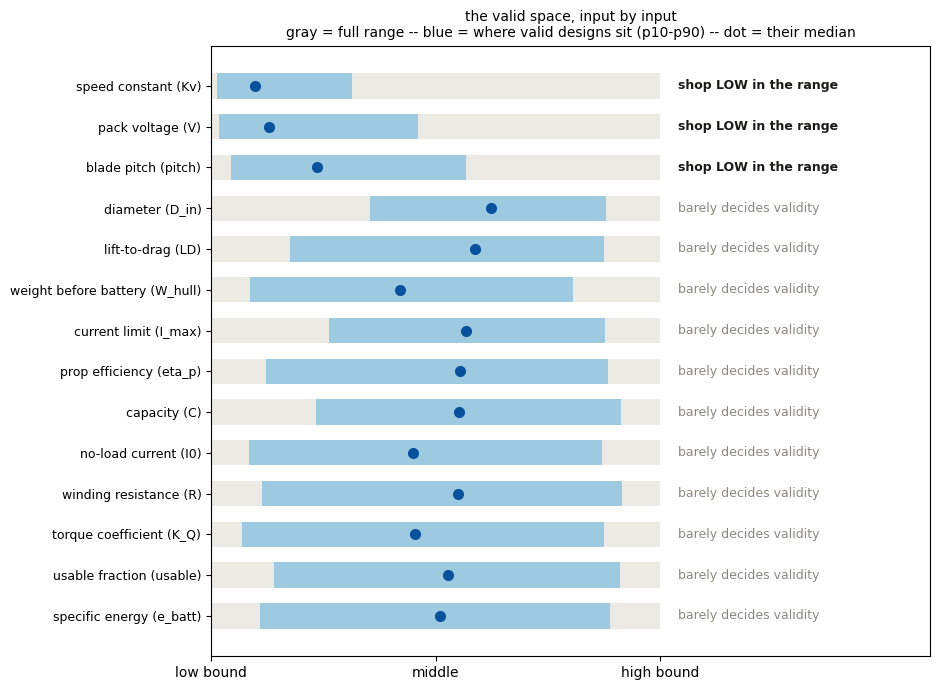

In [12]:
# where the valid designs sit inside each input's range -- the shopping directions
if not valid.any():
    print("no valid designs: loosen REQS/SANITY or widen the input ranges, then re-run")
else:
    rows = []
    for k in BOUNDS:
        lo, hi = BOUNDS[k]
        p = (samples[k][valid] - lo) / (hi - lo)
        q10, q50, q90 = np.percentile(p, [10, 50, 90])
        rows.append((k, q10, q50, q90, q50 - 0.5))
    rows.sort(key=lambda r: abs(r[4]), reverse=True)

    fig, ax = plt.subplots(figsize=(9.5, 7))
    for i, (k, q10, q50, q90, shift) in enumerate(rows):
        y = len(rows) - 1 - i
        ax.barh(y, 1.0, left=0, height=0.62, color="#eceae5", zorder=1)
        ax.barh(y, q90 - q10, left=q10, height=0.62, color="#9ecae1", zorder=2)
        ax.plot(q50, y, "o", color="#08519c", ms=7, zorder=3)
        if abs(shift) >= 0.2:
            note = "shop HIGH in the range" if shift > 0 else "shop LOW in the range"
            ax.text(1.04, y, note, va="center", fontsize=9, color="#1a1a19", fontweight="bold")
        else:
            ax.text(1.04, y, "barely decides validity", va="center", fontsize=9, color="#8a887f")
    ax.set_yticks([len(rows) - 1 - i for i in range(len(rows))])
    ax.set_yticklabels([f"{LABELS[k]} ({k})" for k, *_ in rows], fontsize=9)
    ax.set_xlim(0, 1.6); ax.set_xticks([0, 0.5, 1.0])
    ax.set_xticklabels(["low bound", "middle", "high bound"])
    ax.set_title("the valid space, input by input\ngray = full range -- blue = where valid designs sit (p10-p90) -- dot = their median",
                 fontsize=10)
    plt.tight_layout(); plt.show()

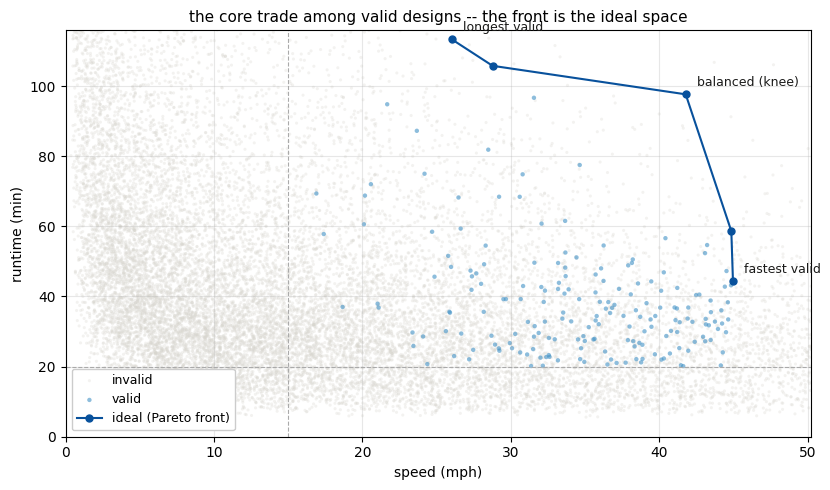

three designs from the ideal front:
                                     fastest valid   balanced (knee)     longest valid
speed constant (Kv)                            460               343               310
winding resistance (R)                      0.0288            0.0182            0.0331
no-load current (I0)                          5.68              3.64              2.17
current limit (I_max)                          223               176              83.1
torque coefficient (K_Q)                    0.0398             0.045            0.0247
diameter (D_in)                               3.87              2.86              4.16
blade pitch (pitch)                           7.96              6.48              6.42
prop efficiency (eta_p)                       0.61             0.658             0.612
pack voltage (V)                              23.8              31.7                20
capacity (C)                                   199               187               184
usable 

In [13]:
# the ideal space: among valid designs, the speed-runtime Pareto front
if valid.any():
    vi = np.where(valid)[0]
    order = vi[np.argsort(-spd[vi])]
    front, best_rt = [], -np.inf
    for i in order:
        if rt[i] > best_rt:
            front.append(i); best_rt = rt[i]
    front = np.array(front)  # speed-descending, runtime-ascending
    knee = front[np.argmax((spd[front] / spd[front].max()) * (rt[front] / rt[front].max()))]
    picks = {"fastest valid": front[0], "balanced (knee)": knee, "longest valid": front[-1]}

    fig, ax = plt.subplots(figsize=(8.5, 5))
    ax.scatter(spd[~valid], rt[~valid], s=5, color="#d8d6cf", alpha=0.3, edgecolors="none", label="invalid")
    ax.scatter(spd[valid], rt[valid], s=10, color="#4292c6", alpha=0.6, edgecolors="none", label="valid")
    ax.plot(spd[front], rt[front], "-o", color="#08519c", ms=5, lw=1.5, label="ideal (Pareto front)")
    for name, i in picks.items():
        ax.annotate(name, (spd[i], rt[i]), xytext=(8, 6), textcoords="offset points",
                    fontsize=9, color="#1a1a19")
    ax.axvline(REQS["min_speed_mph"], color="#aaaaaa", lw=0.8, ls="--")
    ax.axhline(REQS["min_runtime_min"], color="#aaaaaa", lw=0.8, ls="--")
    ax.set_xlim(0, np.percentile(spd[valid], 99) * 1.12)
    ax.set_ylim(0, np.percentile(rt[valid], 99) * 1.18)
    ax.set_xlabel("speed (mph)"); ax.set_ylabel("runtime (min)")
    ax.set_title("the core trade among valid designs -- the front is the ideal space", fontsize=11)
    ax.legend(loc="lower left", fontsize=9, framealpha=1); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    print("three designs from the ideal front:")
    w = max(len(f"{LABELS[k]} ({k})") for k in BOUNDS) + 2
    print(f"{'':<{w}}" + "".join(f"{n:>18}" for n in picks))
    for k in BOUNDS:
        print(f"{LABELS[k] + ' (' + k + ')':<{w}}" +
              "".join(f"{samples[k][i]:>18.3g}" for i in picks.values()))
    print("-" * (w + 18 * len(picks)))
    for label, arr in [("speed (mph)", spd), ("runtime (min)", rt), ("amps (A)", amps),
                       ("weight (lb)", wt), ("motor eff", eff_s), ("slip", slip_s)]:
        print(f"{label:<{w}}" + "".join(f"{arr[i]:>18.3g}" for i in picks.values()))

## 9. What's actually out there: the SSS catalog

Every winding of every SSS motor on the supplier sheet (`sss_motors.csv`), pushed through
the **exact same model and the exact same validity checks** as section 8. The motor's four
numbers (`Kv`, `R`, `I0`, `I_max`) come off the sheet instead of a range; prop, battery and
hull are sampled from their ranges as before, with two reality rules the sheet adds:

- pack voltage is clamped to the winding's `v_max` (you'd buy a pack the motor can take), and
- combos that spin past the winding's `max_rpm` are invalid.

A **combo** is one winding paired with one sampled prop + battery + hull; the combo is
**valid** if it passes all six section-8 checks plus the sheet's `max_rpm`. So "valid %"
is each winding's *room to work with* — the share of the prop/battery/hull space that
keeps it inside the valid space. The winding that tops this table is not "the fastest
motor"; it is the **most forgiving** one — the one that stays valid with the widest
variety of props, batteries and hulls. Which designs are actually *best* is section 10's
job (the ideal set), and the two answers need not be the same winding.

In [14]:
import csv

with open("sss_motors.csv") as f:
    CATALOG = [dict(name=f"{r['motor']} {r['winding']}", Kv=float(r["kv_rpm_per_v"]),
                    R=float(r["r_ohm"]), I0=float(r["i0_a_at_11v"]), I_max=float(r["i_max_a"]),
                    v_max=float(r["v_max_v"]), max_rpm=float(r["max_rpm"]))
               for r in csv.DictReader(f)]
print(f"{len(CATALOG)} windings on the SSS sheet")

NON_MOTOR = [k for k in BOUNDS if k not in MOTOR_BOUNDS]
Nm = 2000
rng2 = np.random.default_rng(1)
sub = {k: rng2.uniform(*BOUNDS[k], Nm) for k in NON_MOTOR}

def run_winding(m):
    res = []
    for i in range(Nm):
        p = {k: sub[k][i] for k in NON_MOTOR}
        p["V"] = min(p["V"], m["v_max"])  # buy a pack the winding can take
        r = steady_state(Kv=m["Kv"], R=m["R"], I0=m["I0"], I_max=m["I_max"], **p)
        r["ok"] = (r["mph"] >= REQS["min_speed_mph"] and r["minutes"] >= REQS["min_runtime_min"]
                   and r["W"] <= REQS["max_weight_lb"] and r["eff"] >= SANITY["min_motor_eff"]
                   and r["slip"] >= SANITY["min_slip"] and r["mph"] <= SANITY["max_speed_mph"]
                   and r["rpm"] <= m["max_rpm"])
        r["inputs"] = p  # the non-motor inputs actually used (V after the v_max clamp)
        res.append(r)
    return res

summary, CAT_VALID = [], []
for m in CATALOG:
    res = run_winding(m)
    ok = [r for r in res if r["ok"]]
    for r in ok:
        CAT_VALID.append(dict(name=m["name"], mph=r["mph"], minutes=r["minutes"], inputs=r["inputs"]))
    summary.append(dict(m=m, frac=len(ok) / Nm,
                        best_mph=max((r["mph"] for r in ok), default=float("nan")),
                        best_min=max((r["minutes"] for r in ok), default=float("nan"))))
summary.sort(key=lambda s: -s["frac"])

n_zero = sum(1 for s in summary if s["frac"] == 0)
print(f"windings with no valid combo at all: {n_zero} of {len(summary)}")
print()
print(f"{'winding':<24}{'Kv':>6}{'v_max':>7}{'I_max':>7}   {'valid':>6}  {'best mph':>9}{'best min':>9}")
for s in summary[:12]:
    m = s["m"]
    print(f"{m['name']:<24}{m['Kv']:>6.0f}{m['v_max']:>7.0f}{m['I_max']:>7.0f}   "
          f"{s['frac']:>6.1%}  {s['best_mph']:>9.1f}{s['best_min']:>9.1f}")
print()
print(f"(for scale: random motors drawn from the section-1 ranges are {valid.mean():.1%} valid)")

263 windings on the SSS sheet


windings with no valid combo at all: 164 of 263

winding                     Kv  v_max  I_max    valid   best mph best min
SSS 56133-V2 11Y           200    170    100    15.2%       44.9    182.4
SSS 56154-V2 10Y           200    125    160    13.2%       44.8    193.9
SSS 56154-V2 9Y            220    112    178    12.8%       44.8    148.7
SSS 56154-V2 11Y           180    138    145    12.5%       44.8    172.0
SSS 56133-V2 10Y           230    155    108    12.4%       44.9    140.5
SSS 56133-V2 9Y            270    135    128    12.2%       44.7    139.3
SSS 56154-V2 12Y           165    150    133    11.6%       45.0    206.9
SSS 56154-V2 8Y            250     99    202    11.6%       44.9    160.6
SSS 56123-V1 12Y           230    155     95    10.9%       45.0    144.8
SSS 56123-V2 12Y           230    155     95    10.9%       45.0    144.8
SSS 56123-V1 11Y           250    145    100    10.8%       44.8    174.3
SSS 56123-V2 11Y           250    145    100    10.8%       44.

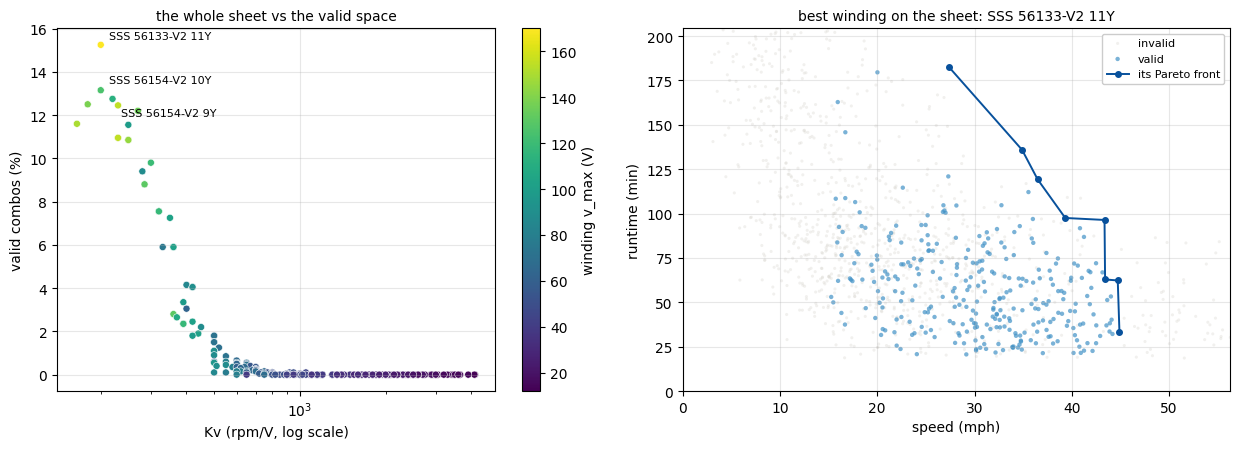

In [15]:
# the catalog in one picture, and what the best winding on the sheet can actually do
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
kv = np.array([s["m"]["Kv"] for s in summary])
fr = np.array([s["frac"] for s in summary])
vm = np.array([s["m"]["v_max"] for s in summary])
sc = ax1.scatter(kv, fr * 100, c=vm, cmap="viridis", s=26, edgecolors="white", linewidths=0.4)
ax1.set_xscale("log")
for s, off in zip(summary[:3], [(6, 4), (6, 5), (6, -12)]):
    ax1.annotate(s["m"]["name"], (s["m"]["Kv"], s["frac"] * 100),
                 xytext=off, textcoords="offset points", fontsize=8)
ax1.set_xlabel("Kv (rpm/V, log scale)"); ax1.set_ylabel("valid combos (%)")
ax1.set_title("the whole sheet vs the valid space", fontsize=10)
ax1.grid(alpha=0.3)
fig.colorbar(sc, ax=ax1, label="winding v_max (V)")

best = summary[0]["m"]
res = run_winding(best)
mphs = np.array([r["mph"] for r in res]); mins = np.array([r["minutes"] for r in res])
okm = np.array([r["ok"] for r in res])
ax2.scatter(mphs[~okm], mins[~okm], s=5, color="#d8d6cf", alpha=0.35, edgecolors="none", label="invalid")
if okm.any():
    ax2.scatter(mphs[okm], mins[okm], s=10, color="#4292c6", alpha=0.7, edgecolors="none", label="valid")
    vi2 = np.where(okm)[0]
    order2 = vi2[np.argsort(-mphs[vi2])]
    front2, brt = [], -np.inf
    for i in order2:
        if mins[i] > brt:
            front2.append(i); brt = mins[i]
    ax2.plot(mphs[front2], mins[front2], "-o", color="#08519c", ms=4, lw=1.4, label="its Pareto front")
    ax2.set_ylim(0, mins[okm].max() * 1.12)
ax2.set_xlim(0, SANITY["max_speed_mph"] * 1.25)
ax2.set_xlabel("speed (mph)"); ax2.set_ylabel("runtime (min)")
ax2.set_title(f"best winding on the sheet: {best['name']}", fontsize=10)
ax2.legend(loc="upper right", fontsize=8, framealpha=1)
ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 10. Are the ideal designs pressed against our bounds?

Every range in this notebook is a guess with a low end and a high end. If the ideal
designs pile up against one end of a range, **that bound — not the physics — is doing the
choosing**: widen it if it was arbitrary, or firm it up if it's a real limit (and then
"buy the bound" is the actual conclusion).

Ideal here = the valid combos pooled across every SSS winding that no other combo beats
by more than 5% on both speed and runtime at once — the thick version of the Pareto front,
using only motors we can actually buy.

5703 valid catalog combos -> 488 ideal (within 5% of the front)
windings in the ideal set: SSS 56154-V2 7Y (32), SSS 56154-V2 8Y (29), SSS 56154-V2 9Y (28), SSS 56154-V2 10Y (26), SSS 56154-V2 6Y (25), SSS 56154-V2 11Y (25) ...



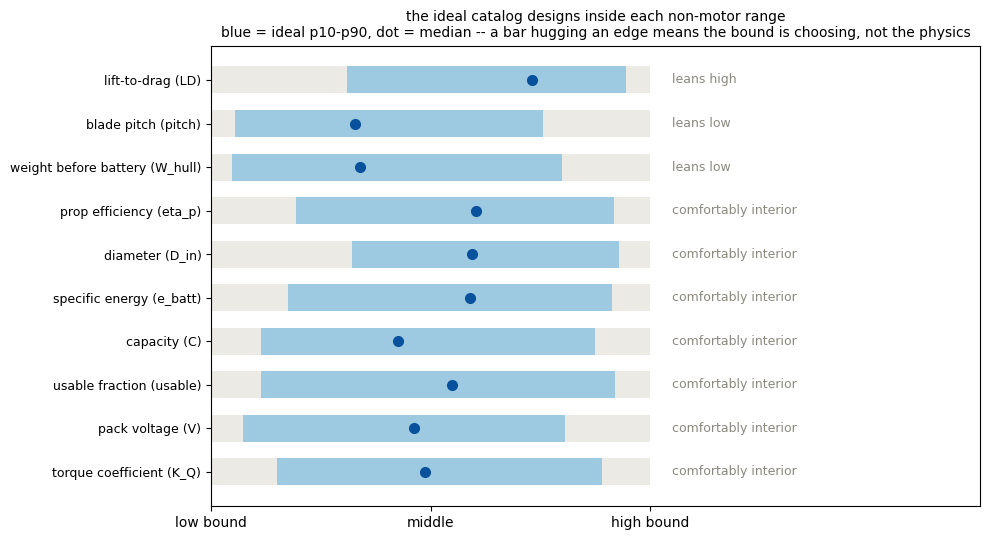


no input is pressed against a bound: the ranges are wide enough that the physics is choosing


In [16]:
from collections import Counter

mph_a = np.array([d["mph"] for d in CAT_VALID])
min_a = np.array([d["minutes"] for d in CAT_VALID])
EPS = 1.05
ideal_mask = np.array([not np.any((mph_a >= m * EPS) & (min_a >= t * EPS))
                       for m, t in zip(mph_a, min_a)])
IDEAL = [d for d, keep in zip(CAT_VALID, ideal_mask) if keep]
print(f"{len(CAT_VALID)} valid catalog combos -> {len(IDEAL)} ideal (within 5% of the front)")
mix = Counter(d["name"] for d in IDEAL).most_common()
print("windings in the ideal set: " + ", ".join(f"{n} ({c})" for n, c in mix[:6])
      + (" ..." if len(mix) > 6 else ""))
print()

rows = []
for k in NON_MOTOR:
    lo, hi = BOUNDS[k]
    pos = np.array([(d["inputs"][k] - lo) / (hi - lo) for d in IDEAL])
    q10, q50, q90 = np.percentile(pos, [10, 50, 90])
    rows.append((k, q10, q50, q90))
rows.sort(key=lambda r: abs(r[2] - 0.5), reverse=True)

def verdict(q50):
    if q50 >= 0.8: return "pressed at the UPPER bound", True
    if q50 <= 0.2: return "pressed at the LOWER bound", True
    if q50 >= 0.65: return "leans high", False
    if q50 <= 0.35: return "leans low", False
    return "comfortably interior", False

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (k, q10, q50, q90) in enumerate(rows):
    y = len(rows) - 1 - i
    ax.barh(y, 1.0, left=0, height=0.62, color="#eceae5", zorder=1)
    ax.barh(y, q90 - q10, left=q10, height=0.62, color="#9ecae1", zorder=2)
    ax.plot(q50, y, "o", color="#08519c", ms=7, zorder=3)
    text, pinned = verdict(q50)
    ax.text(1.05, y, text, va="center", fontsize=9,
            color="#1a1a19" if pinned else "#8a887f",
            fontweight="bold" if pinned else "normal")
ax.set_yticks([len(rows) - 1 - i for i in range(len(rows))])
ax.set_yticklabels([f"{LABELS[k]} ({k})" for k, *_ in rows], fontsize=9)
ax.set_xlim(0, 1.75); ax.set_xticks([0, 0.5, 1.0])
ax.set_xticklabels(["low bound", "middle", "high bound"])
ax.set_title("the ideal catalog designs inside each non-motor range\nblue = ideal p10-p90, dot = median -- a bar hugging an edge means the bound is choosing, not the physics",
             fontsize=10)
plt.tight_layout(); plt.show()

print()
pinned_any = False
for k, q10, q50, q90 in rows:
    text, pinned = verdict(q50)
    if pinned:
        pinned_any = True
        lo, hi = BOUNDS[k]
        med_val = lo + q50 * (hi - lo)
        side = "upper" if q50 >= 0.8 else "lower"
        print(f"{LABELS[k]} ({k}): ideal median {med_val:.3g} {UNITS[k]} -> hugging the {side} "
              f"bound ({lo:g}..{hi:g}): widen it if it was a guess, or buy the bound if it's real")
if not pinned_any:
    print("no input is pressed against a bound: the ranges are wide enough that the physics is choosing")

In [17]:
# the shopping lists: three concrete ideal designs, in full
mphs = np.array([d["mph"] for d in IDEAL]); mins = np.array([d["minutes"] for d in IDEAL])
knee_i = int(np.argmax((mphs / mphs.max()) * (mins / mins.max())))
PICKS = {"fastest ideal": IDEAL[int(np.argmax(mphs))],
         "balanced (knee)": IDEAL[knee_i],
         "longest ideal": IDEAL[int(np.argmax(mins))]}
details = {}
for n, d in PICKS.items():
    m = next(c for c in CATALOG if c["name"] == d["name"])
    details[n] = (m, steady_state(Kv=m["Kv"], R=m["R"], I0=m["I0"], I_max=m["I_max"], **d["inputs"]))

w = 34
def row(label, vals):
    print(f"{label:<{w}}" + "".join(f"{v:>20}" for v in vals))
def sec(title):
    print(); print(f"-- {title} " + "-" * (w + 20 * len(PICKS) - len(title) - 4))

row("", PICKS)
sec("motor (buy this winding)")
row("SSS winding", [d["name"].replace("SSS ", "") for d in PICKS.values()])
row("speed constant Kv (rpm/V)", [f"{m['Kv']:g}" for m, r in details.values()])
row("current limit I_max (A)", [f"{m['I_max']:g}" for m, r in details.values()])
row("winding max voltage (V)", [f"{m['v_max']:g}" for m, r in details.values()])
sec("propeller")
for k in PROP_BOUNDS:
    row(f"{LABELS[k]} ({k}, {UNITS[k]})", [f"{d['inputs'][k]:.3g}" for d in PICKS.values()])
sec("battery")
for k in BATT_BOUNDS:
    row(f"{LABELS[k]} ({k}, {UNITS[k]})", [f"{d['inputs'][k]:.3g}" for d in PICKS.values()])
sec("hull")
for k in HULL_BOUNDS:
    row(f"{LABELS[k]} ({k}, {UNITS[k]})", [f"{d['inputs'][k]:.3g}" for d in PICKS.values()])
sec("what you get")
row("speed (mph)", [f"{r['mph']:.1f}" for m, r in details.values()])
row("runtime (min)", [f"{r['minutes']:.0f}" for m, r in details.values()])
row("steady current (A)", [f"{r['I']:.0f}" for m, r in details.values()])
row("battery weight (lb)", [f"{r['W_batt']:.0f}" for m, r in details.values()])
row("all-up weight (lb)", [f"{r['W']:.0f}" for m, r in details.values()])
row("motor efficiency", [f"{r['eff']:.2f}" for m, r in details.values()])
row("slip (solved)", [f"{r['slip']:.2f}" for m, r in details.values()])

                                         fastest ideal     balanced (knee)       longest ideal

-- motor (buy this winding) ------------------------------------------------------------------
SSS winding                                56154-V2 5Y        56154-V2 12Y        56154-V2 12Y
speed constant Kv (rpm/V)                          400                 165                 165
current limit I_max (A)                            320                 133                 133
winding max voltage (V)                             62                 150                 150

-- propeller ---------------------------------------------------------------------------------
torque coefficient (K_Q, -)                     0.0277              0.0294              0.0376
diameter (D_in, in)                               4.98                4.21                4.05
blade pitch (pitch, in/rev)                       9.03                6.44                6.12
prop efficiency (eta_p, -)                      

## What's deliberately missing

1. **The prop's real curve** — `K_Q` and `η_p` are held constant per prop, but both come
   from the propeller's measured series data and vary with pitch and with how fast the
   boat is already moving. Coupling them (roughly `K_Q ∝ pitch / D`) is the next fidelity step.
2. **Battery discharge limit and sag** — a real pack caps amps on its own and loses volts
   under heavy load; today the motor's `I_max` plays guardrail for both.
3. **A planing check** — `L/D` here assumes the boat *is* on plane; below planing speed the
   water is far less forgiving, so slow solutions are more optimistic than fast ones.
4. **The sheet's other columns** — the SSS CSV also carries continuous/peak power ratings
   and motor weight; none are enforced or counted yet.